# FeatureExtractor — Interactive Test Notebook

This notebook explores the `FeatureExtractor` (single-fn and multi-fn modes) and
`make_statistical_extractor` from the `tensorts` library.

**Sections:**
1. Single-fn mode
2. Multi-fn mode
3. `make_statistical_extractor`
4. Real-world pipeline simulations

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorts import (
    TimeTensor, Dim, FeatureExtractor, make_statistical_extractor,
    Pipeline, PreEmphasis, MelSpectrogram, LogTransform, StandardScaler,
    MinMaxScaler, RobustScaler, SlidingWindow, Flatten, STFT, ChannelSelect,
)

np.random.seed(0)
print("All imports successful.")

All imports successful.


---
## Part 1: FeatureExtractor — Single-fn Mode

In single-fn mode, a single function is applied along `input_dim`.
The consumed axis is replaced by `output_dims`.

### 1a. Fake mel spectrogram (dense)

In [2]:
def mel_like(x, n_mels=64, n_fft=512):
    """Fake mel-spectrogram: STFT power binned into n_mels bands."""
    stft = np.abs(np.fft.rfft(
        np.pad(x, (0, max(0, n_fft - len(x)))), n=n_fft
    )) ** 2
    frames = np.array_split(stft, n_mels)
    return np.array([f.sum() for f in frames])  # (n_mels,)

data = np.random.randn(4, 16000, 1)
ts = TimeTensor(data=data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

print(f"Input shape:  {ts.shape}")
print(f"Input dims:   {ts.dims}")

Input shape:  (4, 16000, 1)
Input dims:   (Dim.BATCH, Dim.TIME, Dim.CHANNEL)


In [3]:
fe = FeatureExtractor(
    fn=mel_like,
    input_dim=Dim.TIME,
    output_dims=(Dim.FREQUENCY,),
    fn_kwargs={"n_mels": 64},
    name="mel_like",
)
result = fe.fit_transform(ts)

print(f"Output shape: {result.shape}")
print(f"Output dims:  {result.dims}")
print(f"Has FREQUENCY dim: {result.has_dim(Dim.FREQUENCY)}")
print(f"Has TIME dim:      {result.has_dim(Dim.TIME)}")

Output shape: (4, 64, 1)
Output dims:  (Dim.BATCH, Dim.FREQUENCY, Dim.CHANNEL)
Has FREQUENCY dim: True
Has TIME dim:      False


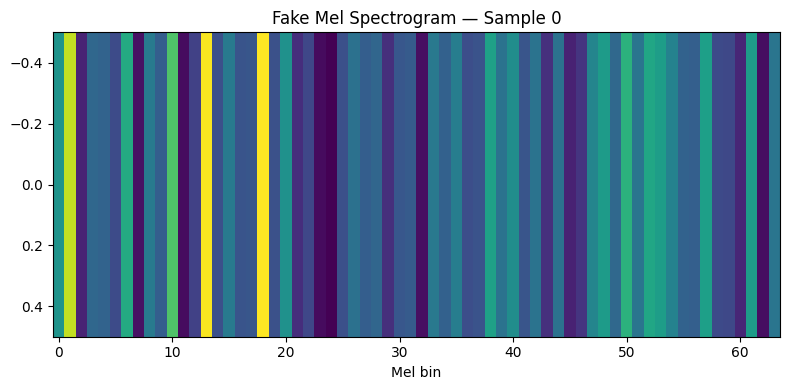

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(result.data[0, :, 0].reshape(-1, 1).T, aspect="auto", cmap="viridis")
ax.set_xlabel("Mel bin")
ax.set_title("Fake Mel Spectrogram — Sample 0")
plt.tight_layout()
plt.show()

### 1b. STFT stereo — both channels preserved

In [5]:
data_stereo = np.random.randn(2, 8000, 2)
ts_stereo = TimeTensor(
    data=data_stereo,
    dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
    channels=["L", "R"],
)
print(f"Input shape: {ts_stereo.shape}, channels: {ts_stereo.channels.names}")

Input shape: (2, 8000, 2), channels: ('L', 'R')


In [6]:
stft_result = STFT(n_fft=512, hop_length=256).fit_transform(ts_stereo)

print(f"Output shape: {stft_result.shape}")
print(f"Output dims:  {stft_result.dims}")
print(f"n_channels:   {stft_result.n_channels}")

Output shape: (2, 257, 30, 2)
Output dims:  (Dim.BATCH, Dim.FREQUENCY, Dim.TIME, Dim.CHANNEL)
n_channels:   2


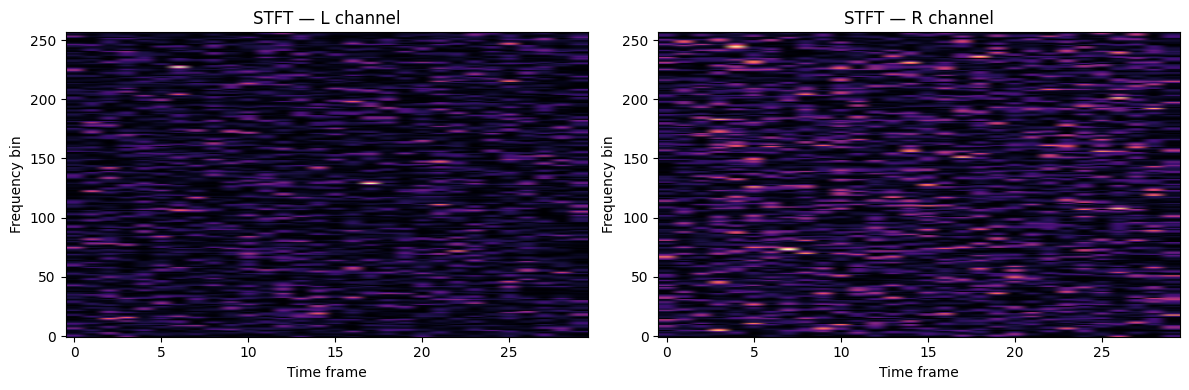

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ch_idx, ch_name in enumerate(["L", "R"]):
    spec = stft_result.data[0, :, :, ch_idx] if stft_result.data.ndim == 4 else stft_result.data[0, :, ch_idx]
    if spec.ndim == 1:
        axes[ch_idx].plot(spec)
        axes[ch_idx].set_title(f"STFT — {ch_name} channel")
    else:
        axes[ch_idx].imshow(spec, aspect="auto", origin="lower", cmap="magma")
        axes[ch_idx].set_title(f"STFT — {ch_name} channel")
        axes[ch_idx].set_ylabel("Frequency bin")
        axes[ch_idx].set_xlabel("Time frame")
plt.tight_layout()
plt.show()

### 1c. Resample via FeatureExtractor

`(T,) -> (T',)` — same dim type, different length.

In [8]:
def resample_fn(x, target=64):
    indices = np.linspace(0, len(x) - 1, target)
    return np.interp(indices, np.arange(len(x)), x)

data_resamp = np.random.randn(5, 200, 3)
ts_resamp = TimeTensor(data=data_resamp, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_resamp = FeatureExtractor(
    fn=resample_fn, input_dim=Dim.TIME,
    output_dims=(Dim.TIME,), fn_kwargs={"target": 64},
)
result_resamp = fe_resamp.fit_transform(ts_resamp)

print(f"Before: {ts_resamp.shape}")
print(f"After:  {result_resamp.shape}")
print(f"Has TIME dim: {result_resamp.has_dim(Dim.TIME)}")

Before: (5, 200, 3)
After:  (5, 64, 3)
Has TIME dim: True


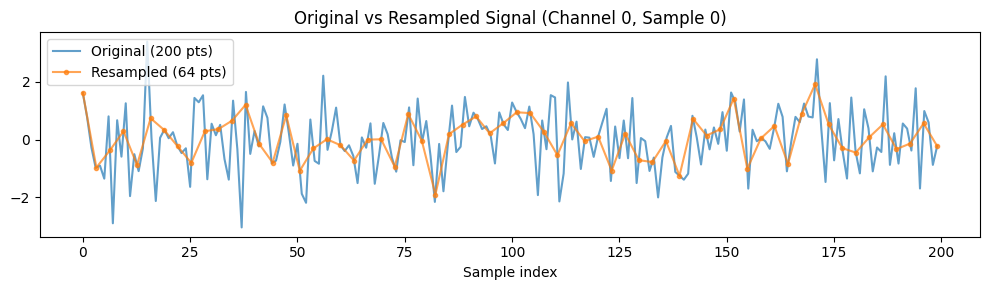

In [9]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(200), ts_resamp.data[0, :, 0], label="Original (200 pts)", alpha=0.7)
ax.plot(np.linspace(0, 199, 64), result_resamp.data[0, :, 0], 'o-', label="Resampled (64 pts)", alpha=0.7, markersize=3)
ax.legend()
ax.set_title("Original vs Resampled Signal (Channel 0, Sample 0)")
ax.set_xlabel("Sample index")
plt.tight_layout()
plt.show()

### 1d. Scalar output

`output_dims=()`: `(B, T, C) -> (B, C)` — TIME axis removed entirely.

In [10]:
energy_fe = FeatureExtractor(
    fn=lambda x: np.sum(x ** 2),
    input_dim=Dim.TIME,
    output_dims=(),
    name="energy",
)

data_scalar = np.random.randn(6, 100, 4)
ts_scalar = TimeTensor(data=data_scalar, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
result_scalar = energy_fe.fit_transform(ts_scalar)

print(f"Before: {ts_scalar.shape}")
print(f"After:  {result_scalar.shape}")
print(f"Has TIME:    {result_scalar.has_dim(Dim.TIME)}")
print(f"Has CHANNEL: {result_scalar.has_dim(Dim.CHANNEL)}")
print(f"Has FEATURE: {result_scalar.has_dim(Dim.FEATURE)}")
print(f"\nEnergy per sample per channel:")
print(result_scalar.data)

Before: (6, 100, 4)
After:  (6, 4)
Has TIME:    False
Has CHANNEL: True
Has FEATURE: False

Energy per sample per channel:
[[ 97.77222962 102.63305716 112.83983546  90.31445427]
 [100.33669466 106.74915551  89.47115144  76.75732714]
 [101.83656524  86.78826215  89.48082998  98.37964771]
 [ 88.36343635 120.3952602   97.20674188  86.4779582 ]
 [130.89804318 101.91997575  80.59394738  82.147734  ]
 [ 97.72704071 105.06849205  99.78084554  82.32603856]]


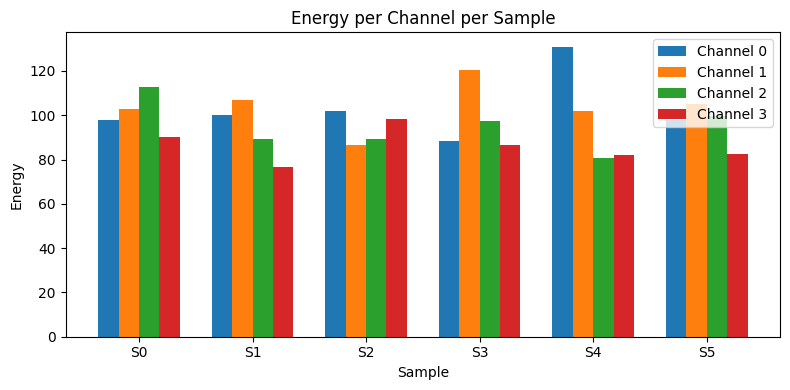

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x_pos = np.arange(result_scalar.shape[0])
width = 0.18
for ch in range(result_scalar.shape[1]):
    ax.bar(x_pos + ch * width, result_scalar.data[:, ch], width, label=f"Channel {ch}")
ax.set_xlabel("Sample")
ax.set_ylabel("Energy")
ax.set_title("Energy per Channel per Sample")
ax.set_xticks(x_pos + width * 1.5)
ax.set_xticklabels([f"S{i}" for i in range(result_scalar.shape[0])])
ax.legend()
plt.tight_layout()
plt.show()

### 1e. Windowed input (B, W, T, C)

Leading dims are preserved: `(4, 10, 512, 1) -> (4, 10, 32, 1)`.

In [12]:
def mel_stub(x, n_mels=32, n_fft=128):
    stft = np.abs(np.fft.rfft(np.pad(x, (0, max(0, n_fft - len(x)))), n=n_fft)) ** 2
    frames = np.array_split(stft, n_mels)
    return np.array([f.sum() for f in frames])

data_win = np.random.randn(4, 10, 512, 1)
ts_win = TimeTensor(data=data_win, dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL))

fe_win = FeatureExtractor(
    fn=mel_stub, input_dim=Dim.TIME,
    output_dims=(Dim.FREQUENCY,), fn_kwargs={"n_mels": 32},
)
result_win = fe_win.fit_transform(ts_win)

print(f"Input shape:  {ts_win.shape}")
print(f"Input dims:   {ts_win.dims}")
print(f"Output shape: {result_win.shape}")
print(f"Output dims:  {result_win.dims}")
print(f"Has WINDOW:    {result_win.has_dim(Dim.WINDOW)}")
print(f"Has FRAME:    {result_win.has_dim(Dim.FRAME)}")
print(f"Has FREQUENCY: {result_win.has_dim(Dim.FREQUENCY)}")

Input shape:  (4, 10, 512, 1)
Input dims:   (Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL)
Output shape: (4, 10, 32, 1)
Output dims:  (Dim.BATCH, Dim.WINDOW, Dim.FREQUENCY, Dim.CHANNEL)
Has WINDOW:    True
Has FRAME:    True
Has FREQUENCY: True


### 1f. Scalar on windowed: (B, W, T, C) -> (B, W, C)

RMS per window.

In [13]:
data_ws = np.random.randn(4, 10, 128, 6)
ts_ws = TimeTensor(data=data_ws, dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL))

rms_fe = FeatureExtractor(
    fn=lambda x: float(np.sqrt(np.mean(x**2))),
    input_dim=Dim.TIME, output_dims=(),
)
result_ws = rms_fe.fit_transform(ts_ws)

print(f"Input shape:  {ts_ws.shape}")
print(f"Output shape: {result_ws.shape}")
print(f"Has TIME: {result_ws.has_dim(Dim.TIME)}")

Input shape:  (4, 10, 128, 6)
Output shape: (4, 10, 6)
Has TIME: False


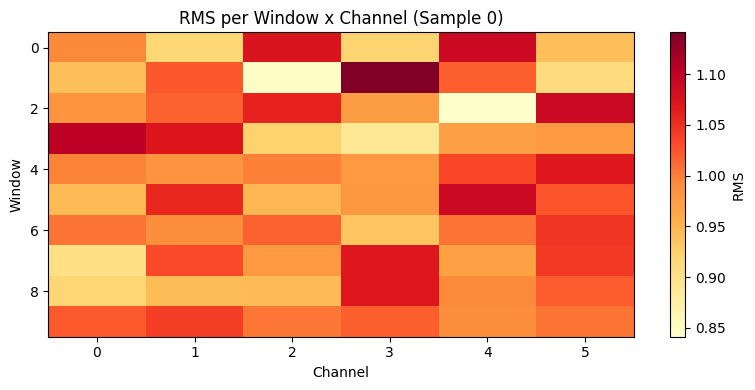

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(result_ws.data[0], aspect="auto", cmap="YlOrRd")
ax.set_xlabel("Channel")
ax.set_ylabel("Window")
ax.set_title("RMS per Window x Channel (Sample 0)")
plt.colorbar(im, ax=ax, label="RMS")
plt.tight_layout()
plt.show()

### 1g. Ragged single-fn: mel

Variable-length samples produce fixed-size output.

In [15]:
def mel_stub_ragged(x, n_mels=32):
    stft = np.abs(np.fft.rfft(x, n=256)) ** 2
    return np.array([g.sum() for g in np.array_split(stft, n_mels)])

samples_ragged = [np.random.randn(np.random.randint(800, 2000)) for _ in range(5)]
ts_ragged = TimeTensor.from_ragged([s[:, np.newaxis] for s in samples_ragged])

print("Sample lengths before:")
for i, s in enumerate(samples_ragged):
    print(f"  Sample {i}: {len(s)} timesteps")
print(f"Is ragged: {ts_ragged.is_ragged}")

Sample lengths before:
  Sample 0: 1907 timesteps
  Sample 1: 1737 timesteps
  Sample 2: 1686 timesteps
  Sample 3: 1929 timesteps
  Sample 4: 1954 timesteps
Is ragged: True


In [16]:
fe_ragged = FeatureExtractor(
    fn=mel_stub_ragged, input_dim=Dim.TIME,
    output_dims=(Dim.FREQUENCY,),
)
result_ragged = fe_ragged.fit_transform(ts_ragged)

print(f"Output shape: {result_ragged.shape}")
print(f"Is ragged:    {result_ragged.is_ragged}")
print("All samples now have uniform shape (32 mel bins).")

Output shape: (5, 32, 1)
Is ragged:    False
All samples now have uniform shape (32 mel bins).


### 1h. Ragged scalar: energy per channel

`y` labels are preserved through the transform.

In [17]:
samples_rag_sc = [np.random.randn(np.random.randint(50, 200), 3) for _ in range(6)]
y_rag = np.array([0, 1, 2, 0, 1, 2])
ts_rag_sc = TimeTensor.from_ragged(samples_rag_sc, y=y_rag)

fe_rag_sc = FeatureExtractor(
    fn=lambda x: np.sum(x**2), input_dim=Dim.TIME, output_dims=(),
)
result_rag_sc = fe_rag_sc.fit_transform(ts_rag_sc)

print(f"Output shape: {result_rag_sc.shape}")
print(f"y preserved:  {np.array_equal(result_rag_sc.y, y_rag)}")
print(f"y values:     {result_rag_sc.y}")
print(f"\nEnergy per sample per channel:")
print(result_rag_sc.data)

Output shape: (6, 3)
y preserved:  True
y values:     [0 1 2 0 1 2]

Energy per sample per channel:
[[106.27942745 118.87954468 118.4797649 ]
 [ 61.28338453  60.70111576  53.46154531]
 [118.12139863 109.03284252 114.95112598]
 [113.15961644 105.96233338 136.81436646]
 [149.34608018 130.50488215 146.99363504]
 [173.59400554 149.39945942 177.64005978]]


---
## Part 2: FeatureExtractor — Multi-fn Mode

In multi-fn mode, each function returns a scalar or 1-D vector per channel.
Results are concatenated along `Dim.FEATURE`.

### 2a. All-scalar functions (dense)

In [18]:
data_mf = np.random.randn(6, 100, 3)
ts_mf = TimeTensor(
    data=data_mf, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
    channels=["a", "b", "c"],
)

fe_mf = FeatureExtractor(
    functions=[
        ("mean",   np.mean),
        ("std",    np.std),
        ("energy", lambda x: float(np.sum(x**2))),
    ],
    input_dim=Dim.TIME,
)
result_mf = fe_mf.fit_transform(ts_mf)

print(f"Output shape:       {result_mf.shape}  (B=6, K=3 features, C=3 channels)")
print(f"Output dims:        {result_mf.dims}")
print(f"feature_names_out_: {fe_mf.feature_names_out_}")
print(f"Has FEATURE dim:    {result_mf.has_dim(Dim.FEATURE)}")
print(f"Has TIME dim:       {result_mf.has_dim(Dim.TIME)}")

Output shape:       (6, 3, 3)  (B=6, K=3 features, C=3 channels)
Output dims:        (Dim.BATCH, Dim.FEATURE, Dim.CHANNEL)
feature_names_out_: ['mean', 'std', 'energy']
Has FEATURE dim:    True
Has TIME dim:       False


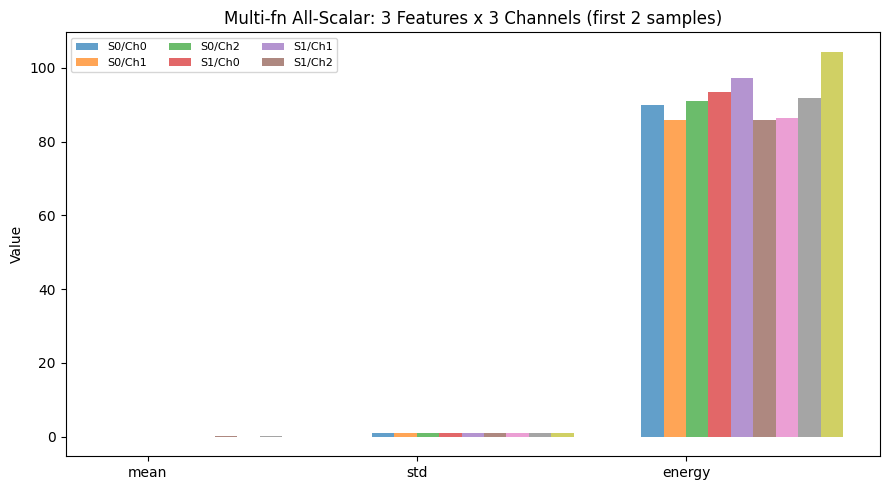

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
feature_names = fe_mf.feature_names_out_
n_features = len(feature_names)
n_channels = result_mf.shape[2]
x_pos = np.arange(n_features)
width = 0.25

for s in range(min(3, result_mf.shape[0])):
    for ch in range(n_channels):
        offset = (s * n_channels + ch) * width / n_channels
        ax.bar(x_pos + offset, result_mf.data[s, :, ch], width / n_channels,
               label=f"S{s}/Ch{ch}" if s < 2 else None, alpha=0.7)

ax.set_xticks(x_pos + width / 2)
ax.set_xticklabels(feature_names)
ax.set_title("Multi-fn All-Scalar: 3 Features x 3 Channels (first 2 samples)")
ax.set_ylabel("Value")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

### 2b. Mixed scalar + vector function

In [20]:
def top3_fft(x):
    return np.sort(np.abs(np.fft.rfft(x)))[-3:]

data_mv = np.random.randn(4, 128, 2)
ts_mv = TimeTensor(data=data_mv, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_mv = FeatureExtractor(
    functions=[
        ("mean", np.mean),       # scalar -> K=1
        ("top3", top3_fft),      # vector -> K=3
    ],
    input_dim=Dim.TIME,
)
result_mv = fe_mv.fit_transform(ts_mv)

print(f"Output shape:       {result_mv.shape}  (B=4, K_total=1+3=4, C=2)")
print(f"feature_names_out_: {fe_mv.feature_names_out_}")

Output shape:       (4, 4, 2)  (B=4, K_total=1+3=4, C=2)
feature_names_out_: ['mean', 'top3__0', 'top3__1', 'top3__2']


### 2c. Windowed multi-fn: (B, W, T, C) -> (B, W, K, C)

In [21]:
data_wmf = np.random.randn(3, 8, 64, 4)
ts_wmf = TimeTensor(data=data_wmf, dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL))

fe_wmf = FeatureExtractor(
    functions=[
        ("mean", np.mean),
        ("rms", lambda x: float(np.sqrt(np.mean(x**2)))),
    ],
    input_dim=Dim.TIME,
)
result_wmf = fe_wmf.fit_transform(ts_wmf)

print(f"Input:  {ts_wmf.shape}  dims={ts_wmf.dims}")
print(f"Output: {result_wmf.shape}  dims={result_wmf.dims}")
print(f"Has WINDOW:  {result_wmf.has_dim(Dim.WINDOW)}")
print(f"Has FEATURE: {result_wmf.has_dim(Dim.FEATURE)}")

Input:  (3, 8, 64, 4)  dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL)
Output: (3, 8, 2, 4)  dims=(Dim.BATCH, Dim.WINDOW, Dim.FEATURE, Dim.CHANNEL)
Has WINDOW:  True
Has FEATURE: True


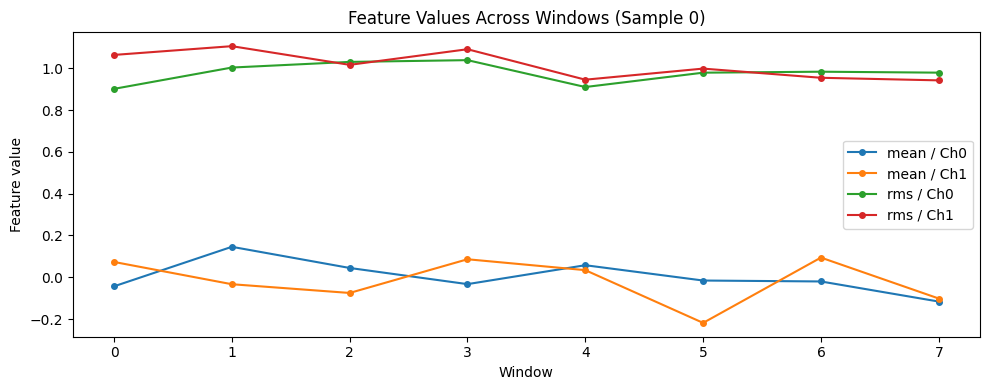

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
for feat_idx, feat_name in enumerate(fe_wmf.feature_names_out_):
    for ch in range(min(2, result_wmf.shape[3])):
        ax.plot(result_wmf.data[0, :, feat_idx, ch],
                label=f"{feat_name} / Ch{ch}", marker='o', markersize=4)
ax.set_xlabel("Window")
ax.set_ylabel("Feature value")
ax.set_title("Feature Values Across Windows (Sample 0)")
ax.legend()
plt.tight_layout()
plt.show()

### 2d. Ragged multi-fn

In [23]:
samples_rmf = [np.random.randn(100 + i * 50, 3) for i in range(5)]
y_rmf = np.array([0, 1, 0, 1, 0])
ts_rmf = TimeTensor.from_ragged(samples_rmf, channels=["x", "y", "z"], y=y_rmf)

fe_rmf = FeatureExtractor(
    functions=[("mean", np.mean), ("std", np.std), ("min", np.min)],
    input_dim=Dim.TIME,
)
result_rmf = fe_rmf.fit_transform(ts_rmf)

print(f"Output shape: {result_rmf.shape}  (B=5, K=3 fns, C=3 channels)")
print(f"Is ragged:    {result_rmf.is_ragged}")
print(f"y preserved:  {np.array_equal(result_rmf.y, y_rmf)}")

Output shape: (5, 3, 3)  (B=5, K=3 fns, C=3 channels)
Is ragged:    False
y preserved:  True


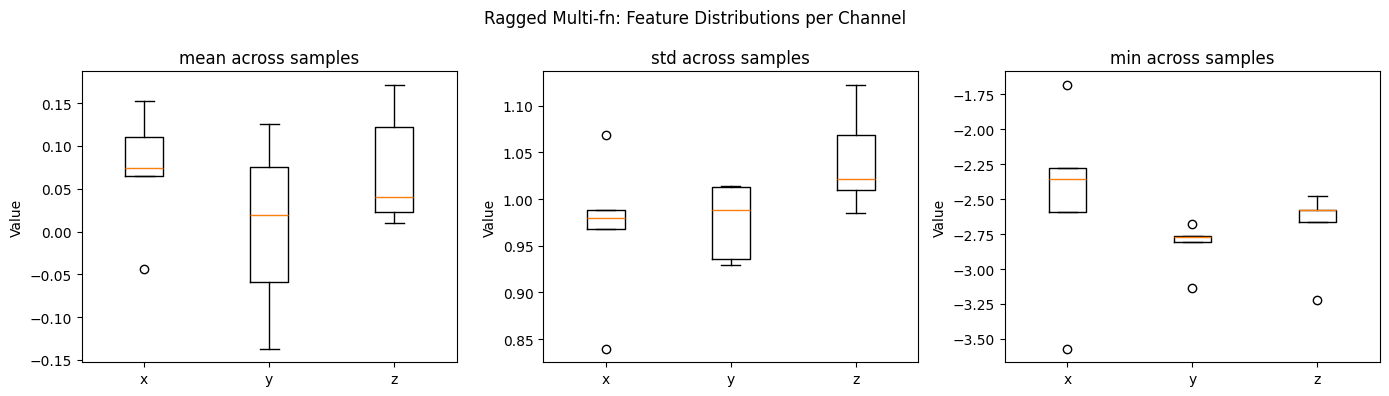

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feat_idx, feat_name in enumerate(fe_rmf.feature_names_out_):
    bp_data = [result_rmf.data[:, feat_idx, ch] for ch in range(3)]
    axes[feat_idx].boxplot(bp_data, tick_labels=["x", "y", "z"])
    axes[feat_idx].set_title(f"{feat_name} across samples")
    axes[feat_idx].set_ylabel("Value")
plt.suptitle("Ragged Multi-fn: Feature Distributions per Channel")
plt.tight_layout()
plt.show()

### 2e. Per-function kwargs (3-tuples)

In [25]:
def top_k(x, k=5):
    return np.sort(np.abs(x))[-k:]

data_kw = np.random.randn(3, 100, 2)
ts_kw = TimeTensor(data=data_kw, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_kw = FeatureExtractor(
    functions=[
        ("mean",  np.mean),
        ("top3",  top_k, {"k": 3}),
        ("top5",  top_k, {"k": 5}),
    ],
    input_dim=Dim.TIME,
)
result_kw = fe_kw.fit_transform(ts_kw)

print(f"Output shape: {result_kw.shape}  (K_total = 1 + 3 + 5 = 9)")
print(f"\nAll feature names:")
for name in fe_kw.feature_names_out_:
    print(f"  {name}")

Output shape: (3, 9, 2)  (K_total = 1 + 3 + 5 = 9)

All feature names:
  mean
  top3__0
  top3__1
  top3__2
  top5__0
  top5__1
  top5__2
  top5__3
  top5__4


### 2f. Channel names preserved

In [26]:
data_ch = np.random.randn(4, 100, 3)
ts_ch = TimeTensor(
    data=data_ch, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
    channels=["acc_x", "acc_y", "acc_z"],
)

fe_ch = FeatureExtractor(
    functions=[("mean", np.mean), ("std", np.std)],
    input_dim=Dim.TIME,
)
result_ch = fe_ch.fit_transform(ts_ch)

print(f"Output shape:   {result_ch.shape}")
print(f"Channel names:  {result_ch.channels.names}")
print(f"Feature count:  {result_ch.shape[1]}")

Output shape:   (4, 2, 3)
Channel names:  ('acc_x', 'acc_y', 'acc_z')
Feature count:  2


### 2g. get_params / set_params / clone

In [29]:
from sklearn.base import clone

fe_clone = FeatureExtractor(
    functions=[("mean", np.mean), ("std", np.std)],
    input_dim=Dim.TIME,
)

params = fe_clone.get_params()
print("get_params():")
for k, v in params.items():
    print(f"  {k}: {v}")

fe_cloned = clone(fe_clone)
print(f"\nCloned successfully: {fe_cloned.functions is not None}")
print(f"Clone mode: {fe_cloned._mode}")

get_params():
  fn: None
  input_dim: Dim.TIME
  output_dims: (Dim.TIME,)
  fn_args: ()
  fn_kwargs: {}
  name: None
  functions: [('mean', <function mean at 0x10427a6b0>), ('std', <function std at 0x10427a830>)]
  scope: Scope.PER_CHANNEL

Cloned successfully: True
Clone mode: multi


### 2h. Error cases

In [30]:
# Error 1: fn AND functions both set -> ValueError
try:
    FeatureExtractor(fn=np.mean, functions=[("mean", np.mean)], input_dim=Dim.TIME)
    print("ERROR: Should have raised ValueError!")
except ValueError as e:
    print(f"Correctly raised ValueError: {e}")

Correctly raised ValueError: Provide either 'fn' (single-fn mode) or 'functions' (multi-fn mode), not both.


In [31]:
# Error 2: functions=[] -> ValueError
try:
    FeatureExtractor(functions=[], input_dim=Dim.TIME)
    print("ERROR: Should have raised ValueError!")
except ValueError as e:
    print(f"Correctly raised ValueError: {e}")

Correctly raised ValueError: 'functions' must not be empty.


---
## Part 3: make_statistical_extractor

Factory function that creates a multi-fn FeatureExtractor pre-loaded with
built-in statistical functions and/or custom callables.

### 3a. Default features

In [32]:
data_stat = np.random.randn(5, 100, 3)
ts_stat = TimeTensor(data=data_stat, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_stat = make_statistical_extractor()
result_stat = fe_stat.fit_transform(ts_stat)

print(f"Output shape:       {result_stat.shape}  (B=5, K=4 defaults, C=3)")
print(f"feature_names_out_: {fe_stat.feature_names_out_}")

Output shape:       (5, 4, 3)  (B=5, K=4 defaults, C=3)
feature_names_out_: ['mean', 'std', 'min', 'max']


### 3b. All 13 built-in features

In [45]:
all_features = [
    "mean", "std", "var", "min", "max", "median",
    "rms", "range", "energy", "skew", "kurtosis", "iqr", "zcr",
]

# data_all = np.random.randn(1, 4, 200, 2)
# ts_all = TimeTensor(data=data_all, dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL))
data_all = np.random.randn(4, 200, 2)
ts_all = TimeTensor(data=data_all, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_all = make_statistical_extractor(all_features)
result_all = fe_all.fit_transform(ts_all)

print(f"Output shape:       {result_all.shape}  (B=4, K=13, C=2)")
print(f"feature_names_out_: {fe_all.feature_names_out_}")

Output shape:       (4, 13, 2)  (B=4, K=13, C=2)
feature_names_out_: ['mean', 'std', 'var', 'min', 'max', 'median', 'rms', 'range', 'energy', 'skew', 'kurtosis', 'iqr', 'zcr']


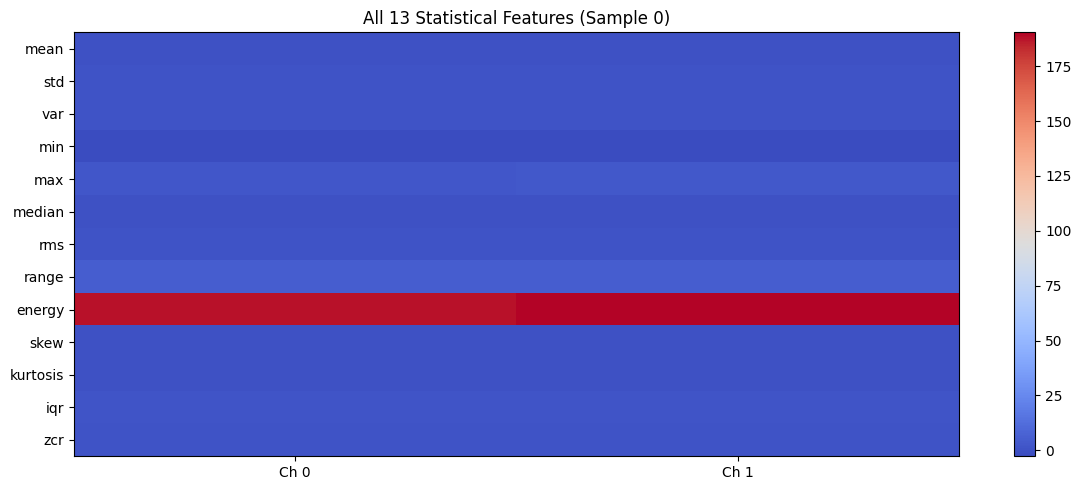

In [47]:
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(result_all.data[0, :, :], aspect="auto", cmap="coolwarm")
ax.set_yticks(range(13))
ax.set_yticklabels(all_features)
ax.set_xticks(range(2))
ax.set_xticklabels([f"Ch {i}" for i in range(2)])
ax.set_title("All 13 Statistical Features (Sample 0)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

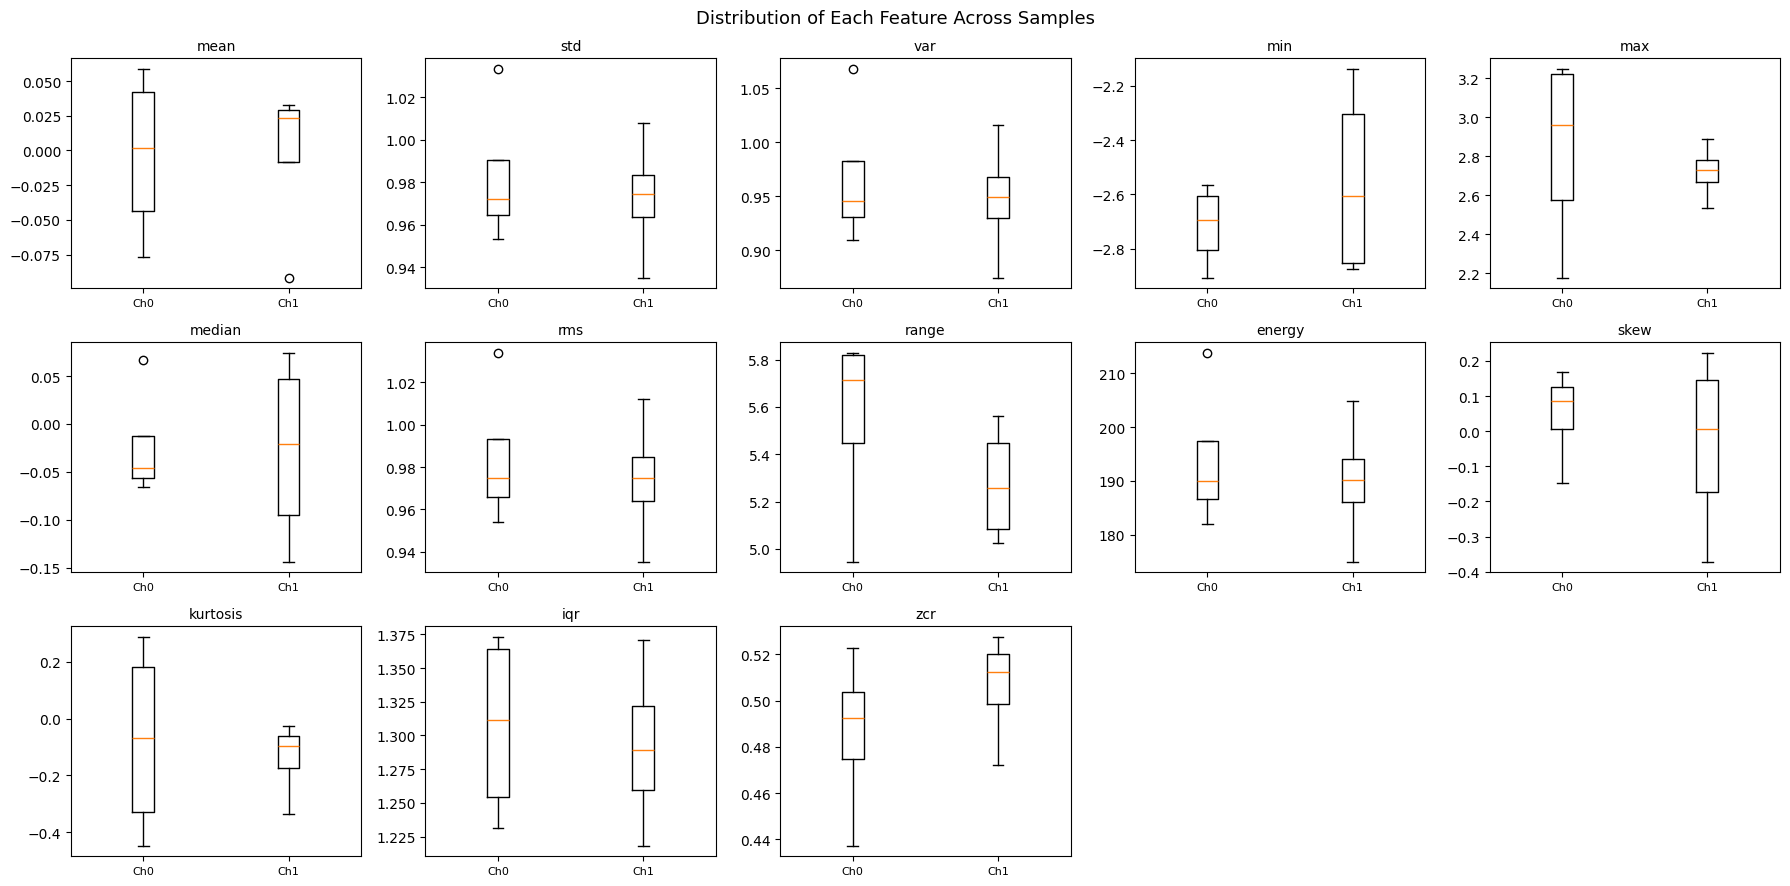

In [48]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
axes = axes.flatten()
for feat_idx in range(13):
    vals = result_all.data[:, feat_idx, :]  # (B, C)
    axes[feat_idx].boxplot(vals)
    axes[feat_idx].set_title(all_features[feat_idx], fontsize=10)
    axes[feat_idx].set_xticklabels([f"Ch{i}" for i in range(vals.shape[1])], fontsize=8)
# Hide unused subplots
for idx in range(13, 15):
    axes[idx].set_visible(False)
plt.suptitle("Distribution of Each Feature Across Samples", fontsize=13)
plt.tight_layout()
plt.show()

### 3c. Ragged input

In [54]:
samples_stat_rag = [np.random.randn(np.random.randint(80, 200), 4) for _ in range(10)]
y_stat_rag = np.random.randint(0, 2, 10)
ts_stat_rag = TimeTensor.from_ragged(samples_stat_rag, y=y_stat_rag)

fe_stat_rag = make_statistical_extractor(["mean", "std", "rms"])
result_stat_rag = fe_stat_rag.fit_transform(ts_stat_rag)

print(f"Input shape: {ts_stat_rag.shape}, with lengths: {ts_stat_rag.lengths}")
print(f"Output shape: {result_stat_rag.shape}  (B=10, K=3, C=4)")
print(f"y preserved:  {np.array_equal(result_stat_rag.y, y_stat_rag)}")
print(f"y values:     {result_stat_rag.y}")
print(f"Is ragged: {result_stat_rag.is_ragged}")

Input shape: (10, -1, 4), with lengths: [149, 184, 156, 163, 81, 108, 139, 158, 135, 123]
Output shape: (10, 3, 4)  (B=10, K=3, C=4)
y preserved:  True
y values:     [1 1 1 0 0 1 0 1 1 0]
Is ragged: False


### 3d. Custom callable mixed with built-in

In [55]:
def dominant_freq(x):
    freqs = np.fft.rfftfreq(len(x))
    mag = np.abs(np.fft.rfft(x))
    return float(freqs[np.argmax(mag)])

data_custom = np.random.randn(4, 128, 2)
ts_custom = TimeTensor(data=data_custom, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

fe_custom = make_statistical_extractor([
    "mean",
    ("dominant_freq", dominant_freq),
])
result_custom = fe_custom.fit_transform(ts_custom)

print(f"Output shape:       {result_custom.shape}  (B=4, K=2, C=2)")
print(f"feature_names_out_: {fe_custom.feature_names_out_}")
print(f"\nValues (sample 0):")
for i, name in enumerate(fe_custom.feature_names_out_):
    print(f"  {name}: {result_custom.data[0, i, :]}")

Output shape:       (4, 2, 2)  (B=4, K=2, C=2)
feature_names_out_: ['mean', 'dominant_freq']

Values (sample 0):
  mean: [-0.00323093  0.02462452]
  dominant_freq: [0.234375  0.4453125]


### 3e. Custom with kwargs (3-tuple)

In [70]:
def top_k_energy(x, k=3):
    return np.sort(np.abs(np.fft.rfft(x)))[-k:]

data_3t = np.random.randn(3, 128, 2)
ts_3t = TimeTensor(data=data_3t, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL), channels=["ch0", "ch1"])

fe_3t = make_statistical_extractor([
    "mean",
    ("top5_fft", top_k_energy, {"k": 5}),
])
result_3t = fe_3t.fit_transform(ts_3t)

print(f"Output shape: {result_3t.shape}  (K = 1 + 5 = 6)")
print(f"\nFeature names:")
for name in fe_3t.feature_names_out_:
    print(f"  {name}")

Output shape: (3, 6, 2)  (K = 1 + 5 = 6)

Feature names:
  mean
  top5_fft__0
  top5_fft__1
  top5_fft__2
  top5_fft__3
  top5_fft__4


In [72]:
flat = Flatten()
flat_result_3t = flat.fit_transform(result_3t)

print(f"Output shape: {flat_result_3t.shape}")
print(f"Features: {flat_result_3t.metadata['_feature_names']}")
print(f"Updated from pipeline channel names: {flat_result_3t.channels.names}")

Output shape: (3, 12)
Features: ['mean', 'top5_fft__0', 'top5_fft__1', 'top5_fft__2', 'top5_fft__3', 'top5_fft__4']
Updated from pipeline channel names: ('mean__ch0', 'mean__ch1', 'top5_fft__0__ch0', 'top5_fft__0__ch1', 'top5_fft__1__ch0', 'top5_fft__1__ch1', 'top5_fft__2__ch0', 'top5_fft__2__ch1', 'top5_fft__3__ch0', 'top5_fft__3__ch1', 'top5_fft__4__ch0', 'top5_fft__4__ch1')


### 3f. Error cases

In [58]:
# Unknown string -> ValueError
try:
    make_statistical_extractor(["mean", "invalid_feature"])
    print("ERROR: Should have raised ValueError!")
except ValueError as e:
    print(f"Correctly raised ValueError: {e}")

Correctly raised ValueError: Unknown built-in feature(s): ['invalid_feature']. Valid: ['energy', 'iqr', 'kurtosis', 'max', 'mean', 'median', 'min', 'range', 'rms', 'skew', 'std', 'var', 'zcr']. Pass custom functions as (name, callable) tuples.


In [59]:
# Bare function without name -> TypeError
try:
    make_statistical_extractor([np.mean])
    print("ERROR: Should have raised TypeError!")
except TypeError as e:
    print(f"Correctly raised TypeError: {e}")

Correctly raised TypeError: Each feature must be a str or (name, fn) / (name, fn, kwargs) tuple; got <function mean at 0x10427a6b0>.
